# Tema 2 · Modelo individual del coste total de siniestralidad — Ejercicio práctico (Python)
**Luiz Luzuriaga** · Máster en Ciencias Actuariales y Financieras · Matemática Actuarial de la Estabilidad y Solvencia

Contenido: (A) cartera de 8 pólizas del taller de Excel, (B) Caso 1 (Vida, 1.000 pólizas), (C) Caso 2 (Accidentes, severidad uniforme),
(D) ejemplo de 3 pólizas, (E) cuándo funciona la Normal: la misma cartera a escala creciente.
Se compara siempre **Normal**, **Gamma trasladada** y **Normal Power** con la distribución **exacta** (convolución) y con **Monte Carlo**.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import fftconvolve

P_NIVEL = 0.995
Z = stats.norm.ppf(P_NIVEL)

def momentos_degenerada(n, q, b):
    """Momentos de S con severidad fija b: n pólizas iguales por grupo (modelo individual)."""
    n, q, b = map(lambda x: np.asarray(x, float), (n, q, b))
    E = n*q*b; V = n*q*(1-q)*b**2; m3 = n*b**3*q*(1-q)*(1-2*q)
    return E, V, m3

def aproximaciones(E, V, m3, p=P_NIVEL):
    sd = np.sqrt(V); g = m3/sd**3; z = stats.norm.ppf(p)
    a, beta, k = 4/g**2, 2/(sd*g), E - 2*sd/g           # Gamma trasladada: S ≈ k + Γ(a, tasa=beta)
    return dict(SD=sd, asimetria=g, Normal=E + z*sd,
                Gamma_tras=k + stats.gamma.ppf(p, a, scale=1/beta),
                Normal_Power=E + sd*(z + g/6*(z**2 - 1)), alpha=a, beta=beta, k=k)

def pmf_exacta(n, q, b, unit):
    """Distribución exacta de S = Σ b_g·Bin(n_g,q_g) por convolución sobre la rejilla `unit`."""
    P = np.ones(1)
    for ng, qg, bg in zip(n, q, b):
        u = int(round(bg/unit)); pm = stats.binom.pmf(np.arange(int(ng)+1), int(ng), qg)
        arr = np.zeros(int(ng)*u + 1); arr[::u] = pm; P = fftconvolve(P, arr); P = np.clip(P, 0, None)
    return P/P.sum()

def var_exacto(P, unit, p=P_NIVEL):
    return unit*int(np.searchsorted(np.cumsum(P), p))

## (A) Cartera de 8 pólizas de vida (taller de Excel)
Severidad degenerada: $X_i=I_i\,b_i$ con $I_i\sim\text{Bernoulli}(q_i)$. Por póliza:
$E(X_i)=q_ib_i$, $\mathrm{Var}(X_i)=q_i(1-q_i)b_i^2$, $\mu_3(X_i)=b_i^3q_i(1-q_i)(1-2q_i)$; al ser independientes, **se suman** esperanzas, varianzas y terceros momentos centrales.

In [2]:
pol = pd.DataFrame({"q": [.0015, .002, .0025, .003, .004, .005, .006, .008],
                    "b": [120e3, 150e3, 100e3, 200e3, 80e3, 250e3, 90e3, 300e3]}, index=range(1, 9))
pol["E"], pol["Var"], pol["mu3"] = momentos_degenerada(1, pol.q, pol.b)
tot = pol[["E", "Var", "mu3"]].sum()
print(pol.assign(**{"E": pol.E.round(1), "Var": pol.Var.round(0), "mu3": pol.mu3.round(0)}).to_string())
print("\nTotales:", tot.round(1).to_dict())
ap8 = aproximaciones(tot.E, tot.Var, tot.mu3)
P8 = pmf_exacta(np.ones(8), pol.q, pol.b, 10_000); VaR8 = var_exacto(P8, 10_000)
res8 = pd.DataFrame({"VaR 99,5 %": [ap8["Normal"], ap8["Gamma_tras"], ap8["Normal_Power"], VaR8]},
                    index=["Normal (TCL)", "Gamma trasladada", "Normal Power", "Exacta (convolución)"])
res8["Capital = VaR − E(S)"] = res8["VaR 99,5 %"] - tot.E
print(f"\nSD(S) = {ap8['SD']:.1f}   asimetría = {ap8['asimetria']:.4f}   Gamma: α = {ap8['alpha']:.4f}, β = {ap8['beta']:.3e}, k = {ap8['k']:.1f}")
res8.round(1)

        q         b       E          Var           mu3
1  0.0015  120000.0   180.0   21567600.0  2.580348e+12
2  0.0020  150000.0   300.0   44910000.0  6.709554e+12
3  0.0025  100000.0   250.0   24937500.0  2.481281e+12
4  0.0030  200000.0   600.0  119640000.0  2.378443e+13
5  0.0040   80000.0   320.0   25497600.0  2.023490e+12
6  0.0050  250000.0  1250.0  310937500.0  7.695703e+13
7  0.0060   90000.0   540.0   48308400.0  4.295583e+12
8  0.0080  300000.0  2400.0  714240000.0  2.108436e+14

Totales: {'E': 5840.0, 'Var': 1310038600.0, 'mu3': 329675366628000.0}

SD(S) = 36194.5   asimetría = 6.9528   Gamma: α = 0.0827, β = 7.947e-06, k = -4571.5


,"VaR 99,5 %",Capital = VaR − E(S)
Normal (TCL),99070.7,93230.7
Gamma trasladada,238948.6,233108.6
Normal Power,335410.7,329570.7
Exacta (convolución),300000.0,294160.0


**Lectura.** Con 8 pólizas y asimetría ≈ 7 la Normal ni se acerca a la cola: el capital que da es una tercera parte del exacto.
La Gamma trasladada (239.000 €) queda por debajo y la Normal Power (335.000 €) por encima del valor exacto (300.000 €): son aproximaciones continuas de una variable que solo toma valores en una rejilla
de 10.000 € y cuyo percentil 99,5 % cae en un **salto** (la probabilidad de 1 siniestro grande es relevante; la de 2 o más, mínima).

## (B) Caso 1 — cartera de Vida de 1.000 pólizas (4 grupos homogéneos)
Dentro de un grupo, $\sum b\,I_j=b\cdot\text{Bin}(n,q)$. Se calcula (i) la Normal del enunciado, (ii) Gamma/NP, (iii) la distribución **exacta** por convolución de las 4 binomiales y (iv) **Monte Carlo** (100.000 escenarios, semilla 123).

In [3]:
g1 = pd.DataFrame({"grupo": list("ABCD"), "n": [500, 300, 150, 50], "q": [.002, .004, .006, .010], "b": [1e5, 1.5e5, 2e5, 3e5]}).set_index("grupo")
g1["E"], g1["Var"], g1["mu3"] = momentos_degenerada(g1.n, g1.q, g1.b)
g1["%Var"] = 100*g1.Var/g1.Var.sum(); g1["%E"] = 100*g1.E/g1.E.sum()
t1 = g1[["E", "Var", "mu3"]].sum(); ap1 = aproximaciones(t1.E, t1.Var, t1.mu3)
print(g1.round(1).to_string()); print("\nE(S) = %.0f  Var(S) = %.0f  SD = %.0f  asimetría = %.4f" % (t1.E, t1.Var, ap1["SD"], ap1["asimetria"]))
P1 = pmf_exacta(g1.n, g1.q, g1.b, 50_000); VaR1 = var_exacto(P1, 50_000)

rng = np.random.default_rng(123); n_sim = 100_000
S = sum(rng.binomial(int(n), q, n_sim)*b for n, q, b in zip(g1.n, g1.q, g1.b))
mc = dict(media=S.mean(), sd=S.std(ddof=1), var995=np.quantile(S, P_NIVEL))
# error típico del cuantil MC por bootstrap de las 100.000 simulaciones
ee = np.std([np.quantile(rng.choice(S, n_sim), P_NIVEL) for _ in range(200)])
res1 = pd.DataFrame({"VaR 99,5 %": [ap1["Normal"], ap1["Gamma_tras"], ap1["Normal_Power"], VaR1, mc["var995"]]},
                    index=["Normal (enunciado)", "Gamma trasladada", "Normal Power", "Exacta (convolución)", "Monte Carlo (100.000)"])
res1["Capital = VaR − E(S)"] = res1["VaR 99,5 %"] - t1.E; res1["Capital / E(S) %"] = 100*res1["Capital = VaR − E(S)"]/t1.E
print(f"\nMonte Carlo: media {mc['media']:.0f}, SD {mc['sd']:.0f}; error típico del VaR MC ≈ {ee:.0f}")
res1.round(1)

         n    q         b         E           Var           mu3  %Var    %E
grupo                                                                      
A      500  0.0  100000.0  100000.0  9.980000e+09  9.940080e+14   8.5  16.4
B      300  0.0  150000.0  180000.0  2.689200e+10  4.001530e+15  22.9  29.5
C      150  0.0  200000.0  180000.0  3.578400e+10  7.070918e+15  30.5  29.5
D       50  0.0  300000.0  150000.0  4.455000e+10  1.309770e+16  38.0  24.6

E(S) = 610000  Var(S) = 117206000000  SD = 342354  asimetría = 0.6271



Monte Carlo: media 608951, SD 342029; error típico del VaR MC ≈ 20878


,"VaR 99,5 %",Capital = VaR − E(S),Capital / E(S) %
Normal (enunciado),1491844.5,881844.5,144.6
Gamma trasladada,1690793.4,1080793.4,177.2
Normal Power,1693480.1,1083480.1,177.6
Exacta (convolución),1700000.0,1090000.0,178.7
Monte Carlo (100.000),1650000.0,1040000.0,170.5


**Lectura.** La Normal da ≈ 1,49 M€ (capital ≈ 0,88 M€, el 145 % de la prima de riesgo), pero la distribución exacta y la simulación sitúan el percentil 99,5 % en **≈ 1,65–1,70 M€** (la simulación cae en uno de los dos escalones contiguos de la rejilla de 50.000 €; su error típico es ≈ 21.000 €).
Con asimetría 0,63 la cola derecha pesa más de lo que supone la simetría de la Normal; la Normal Power y la Gamma trasladada recuperan casi todo ese déficit.
El grupo D (50 pólizas, el 5 % del número de pólizas y el 24,6 % de la prima esperada) aporta el 38 % de la varianza: la severidad entra al cuadrado.

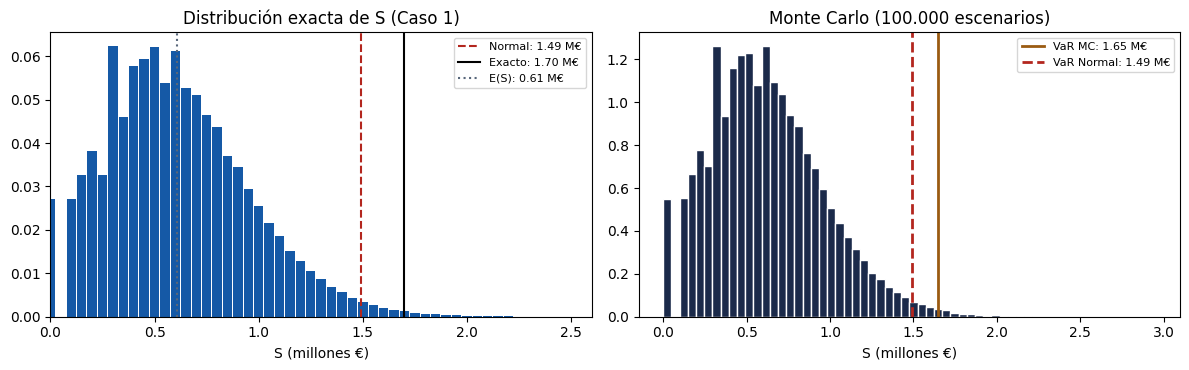

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(len(P1))*50_000/1e6
ax[0].bar(x, P1, width=0.045, color="#1559a6"); ax[0].set_xlim(0, 2.6)
for nombre, v, c, ls in [("Normal", ap1["Normal"], "#b3261e", "--"), ("Exacto", VaR1, "k", "-"), ("E(S)", t1.E, "#57667a", ":")]:
    ax[0].axvline(v/1e6, color=c, ls=ls, label=f"{nombre}: {v/1e6:.2f} M€")
ax[0].set_title("Distribución exacta de S (Caso 1)"); ax[0].set_xlabel("S (millones €)"); ax[0].legend(fontsize=8)
ax[1].hist(S/1e6, bins=60, color="#1b2a4a", edgecolor="white", density=True)
for nombre, v, c, ls in [("VaR MC", mc["var995"], "#9a5b12", "-"), ("VaR Normal", ap1["Normal"], "#b3261e", "--")]:
    ax[1].axvline(v/1e6, color=c, ls=ls, lw=2, label=f"{nombre}: {v/1e6:.2f} M€")
ax[1].set_title("Monte Carlo (100.000 escenarios)"); ax[1].set_xlabel("S (millones €)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## (C) Caso 2 — Accidentes: severidad $B_i\sim U(0,M_i)$
Ahora $\mu_i=M_i/2$ y $\sigma_i^2=M_i^2/12$. Para $X=I\,B$ los momentos crudos son $E[X^k]=q\,M^k/(k+1)$, de donde
$E(X)=q\mu$, $\mathrm{Var}(X)=q\sigma^2+q(1-q)\mu^2$ y $\mu_3(X)=E[X^3]-3E[X]E[X^2]+2E[X]^3$.

In [5]:
g2 = pd.DataFrame({"seg": [1, 2, 3], "n": [100, 200, 50], "q": [.05, .06, .08], "M": [5e3, 8e3, 12e3]}).set_index("seg")
m1, m2, m3c = g2.q*g2.M/2, g2.q*g2.M**2/3, g2.q*g2.M**3/4        # E[X], E[X²], E[X³] por póliza
g2["E"] = g2.n*m1; g2["Var"] = g2.n*(m2 - m1**2); g2["mu3"] = g2.n*(m3c - 3*m1*m2 + 2*m1**3)
t2 = g2[["E", "Var", "mu3"]].sum(); ap2 = aproximaciones(t2.E, t2.Var, t2.mu3)
rng = np.random.default_rng(123)
S2 = np.zeros(n_sim)
for n, q, M in zip(g2.n, g2.q, g2.M):
    k = rng.binomial(int(n), q, n_sim)                                   # nº de siniestros del segmento
    S2 += np.array([rng.uniform(0, M, kk).sum() if kk else 0.0 for kk in k])
res2 = pd.DataFrame({"VaR 99,5 %": [ap2["Normal"], ap2["Gamma_tras"], ap2["Normal_Power"], np.quantile(S2, P_NIVEL)]},
                    index=["Normal (enunciado)", "Gamma trasladada", "Normal Power", "Monte Carlo (100.000)"])
res2["VaR / E(S)"] = res2["VaR 99,5 %"]/t2.E
print(g2.round(1).to_string()); print("\nE(S) = %.0f  Var(S) = %.0f  SD = %.0f  asimetría = %.4f" % (t2.E, t2.Var, ap2["SD"], ap2["asimetria"]))
res2.round(2)

       n    q        M        E          Var           mu3
seg                                                       
1    100  0.0   5000.0  12500.0   40104166.7  1.410156e+11
2    200  0.1   8000.0  48000.0  244480000.0  1.357210e+12
3     50  0.1  12000.0  24000.0  180480000.0  1.462579e+12

E(S) = 84500  Var(S) = 465064167  SD = 21565  asimetría = 0.2952


,"VaR 99,5 %",VaR / E(S)
Normal (enunciado),140048.65,1.66
Gamma trasladada,146002.55,1.73
Normal Power,146027.69,1.73
Monte Carlo (100.000),145107.30,1.72


**Lectura.** $E(S)=84.500$, $\mathrm{Var}(S)=465{,}06\cdot10^6$, $VaR_{99,5\%}^{Normal}\approx140.054$ (VaR/E ≈ 1,66). Aquí la asimetría es mucho menor (≈ 0,3) porque la severidad uniforme está acotada y repartida;
la Normal queda un 3,5 % por debajo de la simulación (140.049 frente a 145.107) y Gamma/NP (146.003 / 146.028) la reproducen, a diferencia del Caso 1.

## (D) Ejemplo de 3 pólizas: la Normal infravalora, pero Gamma y NP sobrestiman
$q=(0{,}01;0{,}02;0{,}03)$, $b=(100.000;150.000;200.000)$.

In [6]:
q3, b3 = np.array([.01, .02, .03]), np.array([1e5, 1.5e5, 2e5])
E3, V3, m33 = momentos_degenerada(1, q3, b3); E3, V3, m33 = E3.sum(), V3.sum(), m33.sum()
P3 = pmf_exacta(np.ones(3), q3, b3, 50_000)
tab = []
for p in (.90, .95, .995):
    a = aproximaciones(E3, V3, m33, p); tab.append([p, a["Normal"], a["Gamma_tras"], a["Normal_Power"], var_exacto(P3, 50_000, p)])
d3 = pd.DataFrame(tab, columns=["p", "Normal", "Gamma tras.", "Normal Power", "Exacto"]).set_index("p")
print(f"E(S) = {E3:.0f}  Var(S) = {V3:.0f}  SD = {V3**.5:.0f}  asimetría = {m33/V3**1.5:.3f}   P(S=0) = {P3[0]:.4f}")
d3.round(0)

E(S) = 10000  Var(S) = 1704000000  SD = 41280  asimetría = 4.152   P(S=0) = 0.9411


,Normal,Gamma tras.,Normal Power,Exacto
p,,,,
0.900,62902.0,50066.0,81251.0,0
0.950,77899.0,88487.0,126616.0,100000
0.995,116329.0,240076.0,277284.0,200000


**Lectura.** Con 3 pólizas $S$ es una variable de 8 valores; $P(S=0)=0{,}94$. El percentil 99,5 % exacto es 200.000 €, la Normal da 116.329 € y la Gamma/NP 240.076 / 277.284 €.
Ninguna aproximación continua es fiable: para carteras diminutas se usa la distribución exacta (convolución, De Pril).

## (E) ¿Cuándo funciona la Normal? La cartera del Caso 1 a escala $k$
Si se multiplica el número de pólizas de cada grupo por $k$, $E$ y $\mathrm{Var}$ crecen como $k$ y la asimetría decrece como $1/\sqrt{k}$ (Lindeberg/TCL).

In [7]:
filas = []
for k in (1, 2, 5, 10, 25, 50):
    nk = g1.n*k; E, V, m3 = momentos_degenerada(nk, g1.q, g1.b); E, V, m3 = E.sum(), V.sum(), m3.sum()
    a = aproximaciones(E, V, m3); v = var_exacto(pmf_exacta(nk, g1.q, g1.b, 50_000), 50_000)
    filas.append([k, int(nk.sum()), a["asimetria"], (a["Normal"]/v - 1)*100, (a["Normal_Power"]/v - 1)*100, (a["Gamma_tras"]/v - 1)*100])
esc = pd.DataFrame(filas, columns=["k", "nº pólizas", "asimetría", "error Normal %", "error NP %", "error Gamma tras. %"]).set_index("k")
esc.round(2)

,nº pólizas,asimetría,error Normal %,error NP %,error Gamma tras. %
k,,,,,
1,1000,0.63,-12.24,-0.38,-0.54
2,2000,0.44,-6.90,0.71,0.65
5,5000,0.28,-3.43,0.45,0.44
10,10000,0.20,-2.32,-0.11,-0.11
25,25000,0.13,-0.96,0.05,0.05
50,50000,0.09,-0.58,-0.03,-0.04


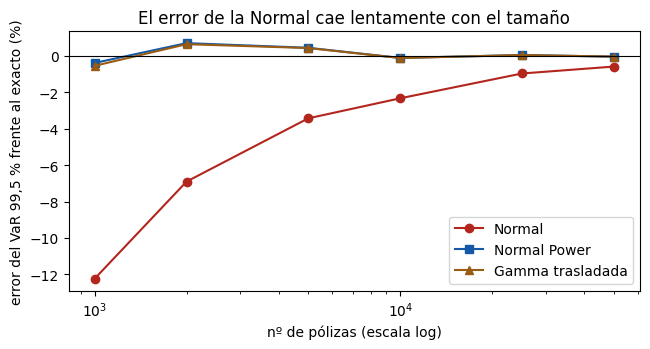

In [8]:
plt.figure(figsize=(6.6, 3.6))
plt.plot(esc["nº pólizas"], esc["error Normal %"], "o-", color="#b3261e", label="Normal")
plt.plot(esc["nº pólizas"], esc["error NP %"], "s-", color="#1559a6", label="Normal Power")
plt.plot(esc["nº pólizas"], esc["error Gamma tras. %"], "^-", color="#9a5b12", label="Gamma trasladada")
plt.axhline(0, color="k", lw=.8); plt.xscale("log"); plt.xlabel("nº de pólizas (escala log)"); plt.ylabel("error del VaR 99,5 % frente al exacto (%)")
plt.legend(); plt.title("El error de la Normal cae lentamente con el tamaño"); plt.tight_layout(); plt.show()

**Lectura.** La Normal subestima el VaR 99,5 % en un 12,2 % con 1.000 pólizas, un 2,3 % con 10.000 y aún un 0,6 % con 50.000: converge despacio porque la asimetría solo cae como $1/\sqrt{n}$.
Las correcciones de tres momentos dejan el error por debajo del 1 % desde el primer tamaño. Todo ello bajo el supuesto de **independencia**: ninguna aproximación ve el riesgo de acumulación.